### Neural network, experimentation tool, version 1

In [115]:
import matplotlib.pyplot as plt
import numpy as np

# activation functions
# ReLu is very simple, it filters out all negative values
# this is a powerful activation function in reality
def activation_ReLu(number):
    if number > 0:
        return number
    else:
        return 0

# we also need a derivated version of ReLu
# otherwise same as original, but instead of origina value, return 1 instead
def activation_ReLu_derivative(number):
    if number > 0:
        return 1
    else:
        return 0

In [116]:
# lock down the randomness in order to get same results everytime
# you can change or disable this if you want
np.random.seed(2026)

def generate_training_data():
    result = []

    # create 100 numbers
    for x in range(100):
        n1 = np.random.randint(0, 5)
        n2 = np.random.randint(3, 7)
        n3 = n1 ** 2 + n2 + np.random.randint(0, 5)

        result.append([n1, n2, n3])

    return result

In [117]:
# initialize weights and biases
# in Keras/TensorFlow/PyTorch etc. these are usually randomized in the beginning
w1 = 1
w2 = 0.5
w3 = 1
w4 = -0.5
w5 = 1
w6 = 1
bias1 = 0.5
bias2 = 0
bias3 = 0.5

# just for comparison after the training
original_w1 = 1
original_w2 = 0.5
original_w3 = 1
original_w4 = -0.5
original_w5 = 1
original_w6 = 1
original_b1 = 0.5
original_b2 = 0
original_b3 = 0.5

# our training data
# x1 = input1, x2 = input2, y = true_value
data = [
    [1, 0, 2],
    [2, 1, 6],
    [3, 3, 17]
]

data = generate_training_data()

# learning rate
LR = 0.0025
epochs = 1000

# let's initialize a list for loss visualizations
loss_points = []

# training loop
for epoch in range(epochs):
    for row in data:
        input1 = row[0]
        input2 = row[1]
        true_value = row[2]

        # NODE 1 OUTPUT
        node_1_output = input1 * w1 + input2 * w3 + bias1
        node_1_output = activation_ReLu(node_1_output)

        # NODE 2 OUTPUT
        node_2_output = input1 * w2 + input2 * w4 + bias2
        node_2_output = activation_ReLu(node_2_output)

        # NODE 3 OUTPUT
        # we can just use Node 1 and 2 outputs, since they already
        # contain the previous weights in their result
        node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
        node_3_output = activation_ReLu(node_3_output)

        # LOSS FUNCTION - we are going to use MSE -> mean squared error
        # MSE formula for LOSS => (predicted_value - true_value)^2
        predicted_value = node_3_output
        loss = (predicted_value - true_value) ** 2

        # BACKPROPAGATION - LAST LAYER FIRST
        # solving the partial derivative of the loss function with respect to w5
        deriv_L_w5 = 2 * node_1_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w5 = w5 - LR * deriv_L_w5

        deriv_L_w6 = 2 * node_2_output * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_w6 = w6 - LR * deriv_L_w6

        deriv_L_b3 = 2 * 1 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        new_b3 = bias3 - LR * deriv_L_b3

        # BACKPROPAGATION - THE FIRST LAYER
        # FROM THIS POINT ONWARD WE HAVE TO USE THE MORE COMPLEX
        # VERSION OF UPDATING THE VALUES => CHAIN RULE

        # weight 1
        deriv_L_w1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input1
        deriv_L_w1 = deriv_L_w1_left * deriv_L_w1_right
        new_w1 = w1 - LR * deriv_L_w1

        # weight 2
        deriv_L_w2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w2_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input1
        deriv_L_w2 = deriv_L_w2_left * deriv_L_w2_right
        new_w2 = w2 - LR * deriv_L_w2

        # weight 3
        deriv_L_w3_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w3_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * input2
        deriv_L_w3 = deriv_L_w3_left * deriv_L_w3_right
        new_w3 = w3 - LR * deriv_L_w3

        # weight 4
        deriv_L_w4_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_w4_right = activation_ReLu_derivative(input1 * w2 + input2 * w4 + bias2) * input2
        deriv_L_w4 = deriv_L_w4_left * deriv_L_w4_right
        new_w4 = w4 - LR * deriv_L_w4

        # bias 1
        deriv_L_b1_left = 2 * w5 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b1_right = activation_ReLu_derivative(input1 * w1 + input2 * w3 + bias1) * 1
        deriv_L_b1 = deriv_L_b1_left * deriv_L_b1_right
        new_b1 = bias1 - LR * deriv_L_b1

        # bias 2
        deriv_L_b2_left = 2 * w6 * (node_1_output * w5 + node_2_output * w6 + bias3 - true_value)
        deriv_L_b2_right = activation_ReLu_derivative(input1 * w2 + input2 * w3 + bias2) * 1
        deriv_L_b2 = deriv_L_b2_left * deriv_L_b2_right
        new_b2 = bias2 - LR * deriv_L_b2

        # ALL DONE! FINALLY UPDATE THE EXISTING WEIGHTS
        w1 = new_w1
        w2 = new_w2
        w3 = new_w3
        w4 = new_w4
        w5 = new_w5
        w6 = new_w6
        bias1 = new_b1
        bias2 = new_b2
        bias3 = new_b3

    loss_points.append(loss)
    print(f"Epoch: {epoch + 1}, loss: {loss}")

Epoch: 1, loss: 0.9939304458397977
Epoch: 2, loss: 1.0746768391086439
Epoch: 3, loss: 0.97276521037638
Epoch: 4, loss: 0.74817041625661
Epoch: 5, loss: 0.6574429399652529
Epoch: 6, loss: 0.5788063907073439
Epoch: 7, loss: 0.514065685561785
Epoch: 8, loss: 0.4559505469165759
Epoch: 9, loss: 0.40262804885713266
Epoch: 10, loss: 0.35379122394915713
Epoch: 11, loss: 0.3094145587090531
Epoch: 12, loss: 0.2694225720852219
Epoch: 13, loss: 0.23363900924075287
Epoch: 14, loss: 0.20181009986809142
Epoch: 15, loss: 0.17363769585147873
Epoch: 16, loss: 0.14880584320269136
Epoch: 17, loss: 0.12699886296101026
Epoch: 18, loss: 0.10791260975165645
Epoch: 19, loss: 0.09126093385387316
Epoch: 20, loss: 0.08924039135698268
Epoch: 21, loss: 0.06812569624374203
Epoch: 22, loss: 0.06533434145509617
Epoch: 23, loss: 0.04828453072847638
Epoch: 24, loss: 0.046496618607802166
Epoch: 25, loss: 0.040631723227945844
Epoch: 26, loss: 0.03456072626522648
Epoch: 27, loss: 0.029046141755136926
Epoch: 28, loss: 0.024

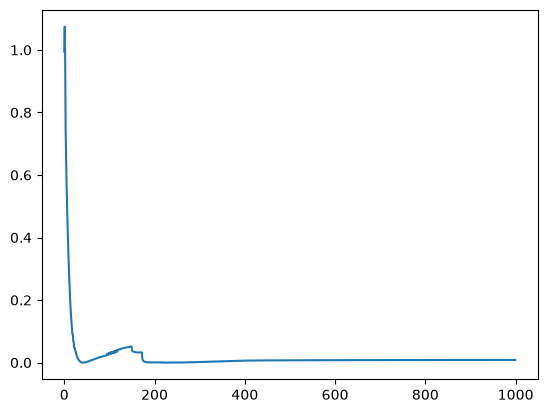

In [118]:
plt.plot(loss_points)

# we can limit the y-axis to see the learning better
# plt.ylim(-1, 3)
plt.show()

In [119]:
print("ORIGINAL WEIGHTS AND BIASES")
print(f"w1: {original_w1}")
print(f"w2: {original_w2}")
print(f"w3: {original_w3}")
print(f"w4: {original_w4}")
print(f"w5: {original_w5}")
print(f"w6: {original_w6}")
print(f"b1: {original_b1}")
print(f"b2: {original_b2}")
print(f"b3: {original_b3}")

print("\n\n##################################")

print("NEW WEIGHTS AND BIASES")
print(f"w1: {w1}")
print(f"w2: {w2}")
print(f"w3: {w3}")
print(f"w4: {w4}")
print(f"w5: {w5}")
print(f"w6: {w6}")
print(f"b1: {bias1}")
print(f"b2: {bias2}")
print(f"b3: {bias3}")


ORIGINAL WEIGHTS AND BIASES
w1: 1
w2: 0.5
w3: 1
w4: -0.5
w5: 1
w6: 1
b1: 0.5
b2: 0
b3: 0.5


##################################
NEW WEIGHTS AND BIASES
w1: 1.22898345467274
w2: 3.409857523332138
w3: 1.3424956547721814
w4: -0.2880847205431717
w5: 0.8924308338008211
w6: 1.2646569465578772
b1: -4.936423997130857
b2: -3.9612859568200873
b3: 5.240922824940038


In [120]:
# prediction function, JUST DO THE FORWARD PASS
# (forward pass again, BUT ONLY THAT!)
def predict(x1, x2):
    input1 = x1
    input2 = x2

    # NODE 1 OUTPUT
    node_1_output = input1 * w1 + input2 * w3 + bias1
    node_1_output = activation_ReLu(node_1_output)

    # NODE 2 OUTPUT
    node_2_output = input1 * w2 + input2 * w4 + bias2
    node_2_output = activation_ReLu(node_2_output)

    # NODE 3 OUTPUT
    # we can just use Node 1 and 2 outputs, since they already
    # contain the previous weights in their result
    node_3_output = node_1_output * w5 + node_2_output * w6 + bias3
    node_3_output = activation_ReLu(node_3_output)
    return node_3_output

In [121]:
result = predict(3, 5)
result

16.22186710474943

In [122]:
data

[[1, 5, 8],
 [0, 4, 8],
 [4, 6, 26],
 [4, 5, 24],
 [0, 4, 4],
 [4, 4, 20],
 [1, 3, 7],
 [0, 3, 4],
 [2, 4, 12],
 [4, 4, 21],
 [0, 4, 4],
 [3, 3, 13],
 [1, 3, 5],
 [3, 5, 17],
 [0, 6, 9],
 [1, 5, 6],
 [2, 5, 9],
 [3, 6, 19],
 [3, 5, 14],
 [2, 3, 11],
 [0, 3, 4],
 [2, 6, 10],
 [3, 4, 17],
 [0, 6, 9],
 [0, 3, 7],
 [3, 6, 17],
 [1, 4, 9],
 [1, 6, 7],
 [3, 4, 14],
 [3, 4, 14],
 [2, 4, 9],
 [3, 6, 15],
 [3, 4, 17],
 [4, 5, 25],
 [2, 3, 11],
 [0, 3, 3],
 [0, 4, 7],
 [1, 4, 9],
 [2, 4, 12],
 [2, 6, 14],
 [3, 6, 17],
 [1, 6, 7],
 [0, 3, 3],
 [2, 6, 13],
 [0, 4, 6],
 [3, 5, 14],
 [1, 3, 4],
 [0, 5, 6],
 [1, 4, 9],
 [4, 6, 26],
 [3, 3, 14],
 [1, 4, 6],
 [4, 4, 20],
 [3, 3, 16],
 [4, 3, 22],
 [1, 6, 8],
 [0, 6, 9],
 [3, 5, 18],
 [1, 5, 6],
 [4, 3, 22],
 [3, 5, 15],
 [1, 6, 9],
 [4, 4, 23],
 [0, 5, 6],
 [0, 6, 6],
 [4, 6, 22],
 [4, 6, 22],
 [3, 5, 14],
 [1, 6, 10],
 [0, 5, 7],
 [1, 3, 8],
 [1, 3, 4],
 [1, 6, 11],
 [3, 4, 16],
 [2, 5, 12],
 [1, 5, 9],
 [1, 4, 6],
 [1, 5, 7],
 [4, 5, 25],
 [4, 4, 21]

### TODO DURING THE NEXT LECTURE

In [123]:
# ideas to try for the next version:

# randomize the starting weights/biases a bit more
# they are a little bit too similar in the beginning (might be detrimental for learning)

# calculate average loss for each epoch, so we get more realistic training metrics

# MOST IMPORTANT! SCALE ALL THE VALUES!! (MinMaxScaling is enough)
# remember also to check how to read prediction outputs after scaling

# FINALLY => use a real dataset => medical insurance dataset (read with pandas)